## Actividad | Dataset - Notebook | Individual

Nombre: Jimena María Suárez Muñoz

Matrícula: A01652504

Fecha: 04/10/2026

## Paso 1. Carga y descripción del dataset

Para esta actividad se utilizará un conjunto de datos que explora como los hábitos de vida afectan el rendimiento academico de los estudiantes. Con 1000 registros de estudiantes y 15 variables, incluyendo horas de estudio, patrones de sueño, uso de redes sociales, calidad de la dieta, salud mental y calificaciones de exámenes finales.

Link de acceso al dataset en Kaggle: https://www.kaggle.com/datasets/jayaantanaath/student-habits-vs-academic-performance

In [140]:
# Cargar librerías

import pandas as pd
import sklearn
import mlflow
import mlflow.sklearn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import cv2
from mlflow.models import infer_signature


In [141]:
# Carga de dataset, determinando la columna "student_id" como el índice

dataset = pd.read_csv("student_habits_performance.csv", index_col="student_id")
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, S1000 to S1999
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   age                            1000 non-null   int64  
 1   gender                         1000 non-null   object 
 2   study_hours_per_day            1000 non-null   float64
 3   social_media_hours             1000 non-null   float64
 4   netflix_hours                  1000 non-null   float64
 5   part_time_job                  1000 non-null   object 
 6   attendance_percentage          1000 non-null   float64
 7   sleep_hours                    1000 non-null   float64
 8   diet_quality                   1000 non-null   object 
 9   exercise_frequency             1000 non-null   int64  
 10  parental_education_level       909 non-null    object 
 11  internet_quality               1000 non-null   object 
 12  mental_health_rating           1000 non-null   i

In [142]:
# Mostrar los primeros 10 registros

dataset.head(10)

,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
student_id,,,,,,,,,,,,,,,
S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4
S1005,24,Male,7.2,1.3,0.0,No,82.9,7.4,Fair,1,Master,Average,4,No,100.0
S1006,21,Female,5.6,1.5,1.4,Yes,85.8,6.5,Good,2,Master,Poor,4,No,89.8
S1007,21,Female,4.3,1.0,2.0,Yes,77.7,4.6,Fair,0,Bachelor,Average,8,No,72.6
S1008,23,Female,4.4,2.2,1.7,No,100.0,7.1,Good,3,Bachelor,Good,1,No,78.9


In [143]:
# Identificar la cantidad de variables numéricas

nums = dataset.select_dtypes(exclude='object').columns
print(f"Tenemos {nums.shape[0]} de columnas numéricas")
nums.tolist()

Tenemos 9 de columnas numéricas


['age',
 'study_hours_per_day',
 'social_media_hours',
 'netflix_hours',
 'attendance_percentage',
 'sleep_hours',
 'exercise_frequency',
 'mental_health_rating',
 'exam_score']

In [144]:
# Tablas de frecuencia de variables categóricas
for col in dataset[nums]:
    print(f'\nRango de valores la variable:\n{col}')
    print(f"[ {dataset[col].min()} - {dataset[col].max()} ]")
    print(".."*20)


Rango de valores la variable:
age
[ 17 - 24 ]
........................................

Rango de valores la variable:
study_hours_per_day
[ 0.0 - 8.3 ]
........................................

Rango de valores la variable:
social_media_hours
[ 0.0 - 7.2 ]
........................................

Rango de valores la variable:
netflix_hours
[ 0.0 - 5.4 ]
........................................

Rango de valores la variable:
attendance_percentage
[ 56.0 - 100.0 ]
........................................

Rango de valores la variable:
sleep_hours
[ 3.2 - 10.0 ]
........................................

Rango de valores la variable:
exercise_frequency
[ 0 - 6 ]
........................................

Rango de valores la variable:
mental_health_rating
[ 1 - 10 ]
........................................

Rango de valores la variable:
exam_score
[ 18.4 - 100.0 ]
........................................


In [145]:
# Identificar la cantidad de variables catégoricas

cats = dataset.select_dtypes(include='object').columns
print(f"Tenemos {cats.shape[0]} columnas categóricas")
cats.tolist()

Tenemos 6 columnas categóricas


['gender',
 'part_time_job',
 'diet_quality',
 'parental_education_level',
 'internet_quality',
 'extracurricular_participation']

In [146]:
# Valor únicos de variables categóricas

for col in dataset[cats]:
    print(f'\nValores únicos de la variable:\n{col}')
    print(dataset[col].unique())
    print(".."*20)


Valores únicos de la variable:
gender
['Female' 'Male' 'Other']
........................................

Valores únicos de la variable:
part_time_job
['No' 'Yes']
........................................

Valores únicos de la variable:
diet_quality
['Fair' 'Good' 'Poor']
........................................

Valores únicos de la variable:
parental_education_level
['Master' 'High School' 'Bachelor' nan]
........................................

Valores únicos de la variable:
internet_quality
['Average' 'Poor' 'Good']
........................................

Valores únicos de la variable:
extracurricular_participation
['Yes' 'No']
........................................


**Descripción del conjunto de datos.**

El conjunto de datos contiene información sobre los hábitos y el desempeño académico de 1,000 estudiantes. 

La variable student_id se utilizó como índice debido a que corresponde a un identificador único y no representa una característica relevante para el entrenamiento del modelo. Después de excluir este identificador, el dataset cuenta con 15 variables, de las cuales 9 son numéricas (int64 o float64) y 6 son categóricas (object). 

Explicación de cada variable:

Numéricas:
- **age**. Edad del estudiante.
- **study_hours_per_day**. Número de horas que el estudiante dedica al estudio por día.
- **social_media_hours**. Número de horas diarias dedicadas al uso de redes sociales.
- **netflix_hours**. Número de horas diarias dedicadas a Netflix.
- **attendance_percentage**. Porcentaje de asistencia del estudiante.
- **sleep_hours**. Número de horas de sueño del estudiante por día.
- **exercise_frequency**. Frecuencia con la que el estudiante realiza ejercicio.
- **mental_health_rating**. Valoración del estado de salud mental del estudiante.
- **exam_score**. Representa el desempeño académico y será utilizada como variable objetivo, por lo que el problema se abordará como una tarea de regresión.

Categóricas:
- **gender**. Género del estudiante.
- **part_time_job**. Indica si el estudiante tiene un trabajo de medio tiempo.
- **diet_quality**. Calidad de la alimentación del estudiante.
- **parental_education_level**. Nivel educativo de los padres del estudiante.
- **internet_quality**. Calidad de la conexión a internet disponible para el estudiante.
- **extracurricular_participation**. Indica si el estudiante participa en actividades extracurriculares.

## Paso 2. Realiza un análisis exploratorio (EDA).

In [147]:
# Mostrar la estadística descriptiva de las variables numéricas

dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1000.0,20.4980,2.308100,17.0,18.750,20.0,23.000,24.0
study_hours_per_day,1000.0,3.5501,1.468890,0.0,2.600,3.5,4.500,8.3
social_media_hours,1000.0,2.5055,1.172422,0.0,1.700,2.5,3.300,7.2
netflix_hours,1000.0,1.8197,1.075118,0.0,1.000,1.8,2.525,5.4
attendance_percentage,1000.0,84.1317,9.399246,56.0,78.000,84.4,91.025,100.0
sleep_hours,1000.0,6.4701,1.226377,3.2,5.600,6.5,7.300,10.0
exercise_frequency,1000.0,3.0420,2.025423,0.0,1.000,3.0,5.000,6.0
mental_health_rating,1000.0,5.4380,2.847501,1.0,3.000,5.0,8.000,10.0
exam_score,1000.0,69.6015,16.888564,18.4,58.475,70.5,81.325,100.0


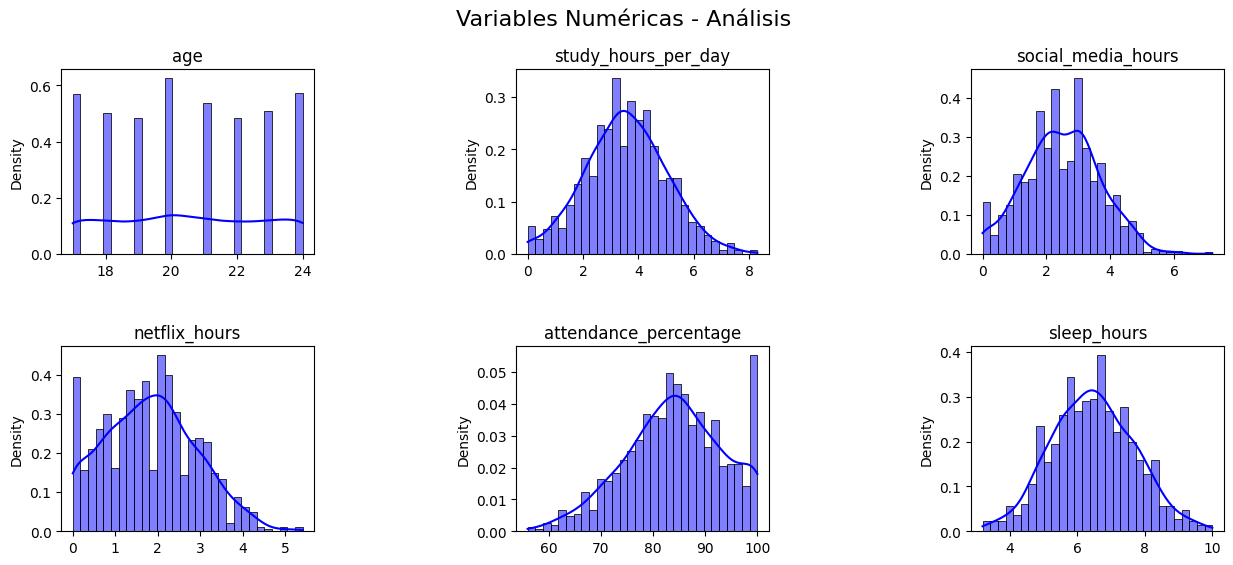

In [148]:
# Análisis de variables Numéricas

fig, axes = plt.subplots(2,3, figsize=(15,6))
fig.suptitle('Variables Numéricas - Análisis', fontsize=16)
plt.subplots_adjust(hspace=0.5, wspace=0.8)
axes = axes.ravel()
for col, ax in zip(dataset[nums], axes):
    sns.histplot(x=dataset[col], ax=ax, bins=30,kde=True,color='blue',stat='density')
    ax.set(title=f'{col}', xlabel=None)

# Los graficos vacíos, descartarlos.
for i in range(len(nums), len(axes)):
    fig.delaxes(axes[i])

In [149]:
# Mostrar la estadística descriptiva de las variables categóricas

dataset.describe(include="object")

,gender,part_time_job,diet_quality,parental_education_level,internet_quality,extracurricular_participation
count,1000,1000,1000,909,1000,1000
unique,3,2,3,3,3,2
top,Female,No,Fair,High School,Good,No
freq,481,785,437,392,447,682


In [150]:
# Tablas de frecuencia de variables categóricas

for col in dataset[cats]:
    print(f'\nFrecuencia de')
    print(dataset[col].value_counts(dropna=False))
    print(".."*20)


Frecuencia de
gender
Female    481
Male      477
Other      42
Name: count, dtype: int64
........................................

Frecuencia de
part_time_job
No     785
Yes    215
Name: count, dtype: int64
........................................

Frecuencia de
diet_quality
Fair    437
Good    378
Poor    185
Name: count, dtype: int64
........................................

Frecuencia de
parental_education_level
High School    392
Bachelor       350
Master         167
NaN             91
Name: count, dtype: int64
........................................

Frecuencia de
internet_quality
Good       447
Average    391
Poor       162
Name: count, dtype: int64
........................................

Frecuencia de
extracurricular_participation
No     682
Yes    318
Name: count, dtype: int64
........................................


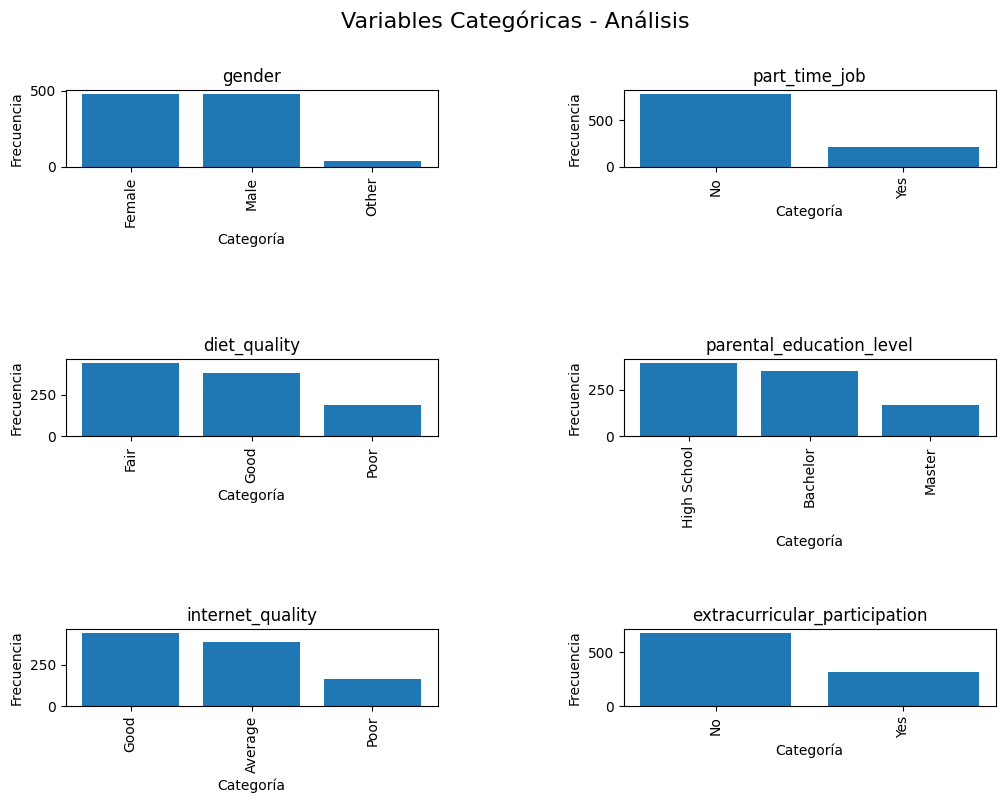

In [151]:
#Revisión de las variables categóricas
fig, axes = plt.subplots(3,2, figsize=(12,8))
fig.suptitle('Variables Categóricas - Análisis', fontsize=16)
plt.subplots_adjust(hspace=2.5, wspace=0.5)
axes = axes.ravel()

# Graficar
for col, ax in zip(dataset[cats], axes):
    value_counts = dataset[col].value_counts()
    x_labels = value_counts.index.astype(str)
    ax.bar(x_labels, value_counts.values)
    ax.set_title(col)
    ax.set_xlabel('Categoría')
    ax.set_ylabel('Frecuencia')
    ax.tick_params(axis='x',rotation=90)

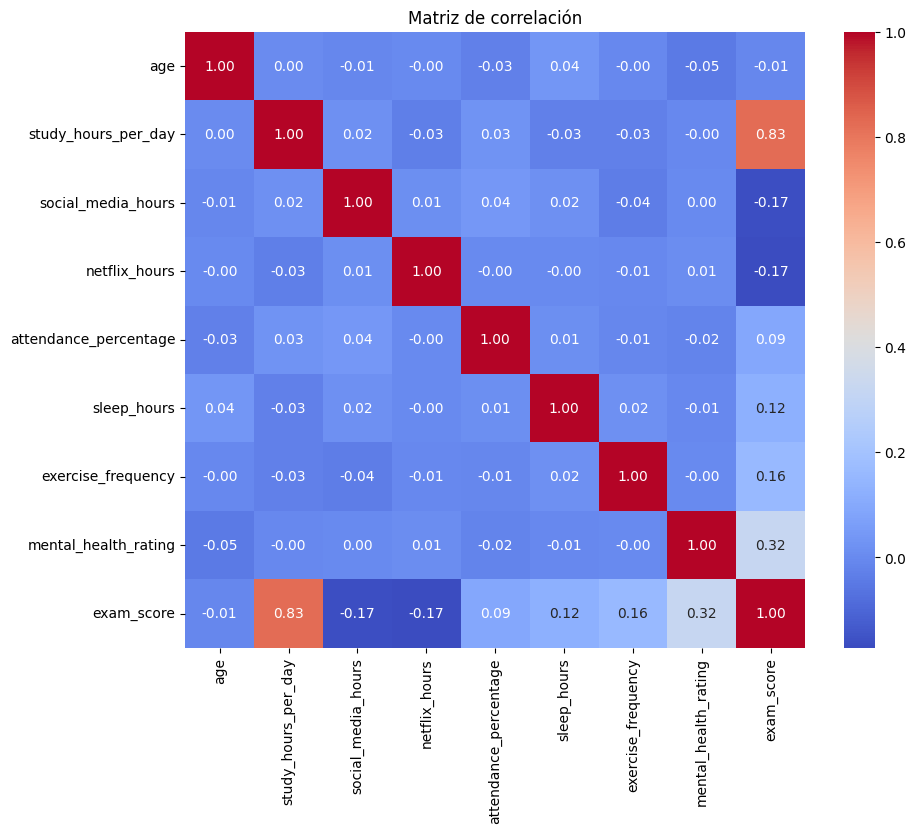

In [152]:
# Calcular la matriz de correlación para las variables numéricas

correlation_matrix = dataset[nums].corr()
correlation_matrix


plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación")
plt.show()

In [153]:
# Características ordenas en base a la variable objetivo

correlation_matrix["exam_score"].sort_values(ascending=False)

exam_score               1.000000
study_hours_per_day      0.825419
mental_health_rating     0.321523
exercise_frequency       0.160107
sleep_hours              0.121683
attendance_percentage    0.089836
age                     -0.008907
social_media_hours      -0.166733
netflix_hours           -0.171779
Name: exam_score, dtype: float64

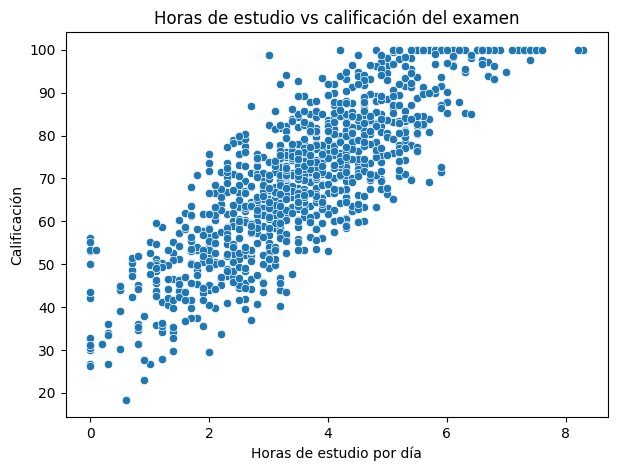

In [154]:
# Gráfica de disperción. Mostrar relación entre
# calificaciones de examenes vs horas de estudio al día

plt.figure(figsize=(7,5))

sns.scatterplot(
    data=dataset,
    x="study_hours_per_day",
    y="exam_score"
)

plt.title("Horas de estudio vs calificación del examen")
plt.xlabel("Horas de estudio por día")
plt.ylabel("Calificación")
plt.show()

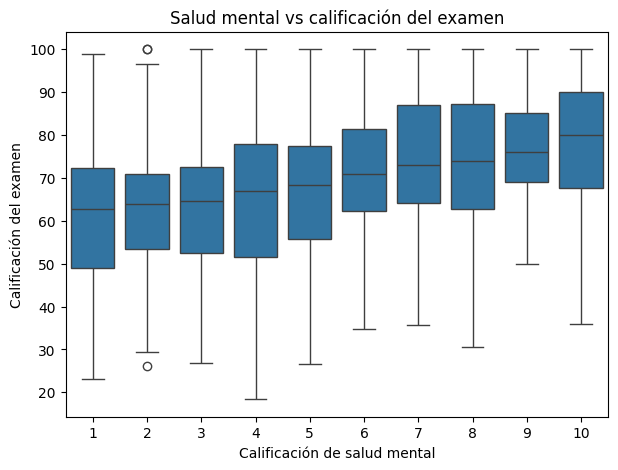

In [155]:
# Gráfica de caja. Mostrar relación entre
# calificaciones de examenes vs estado mental del estudiante

plt.figure(figsize=(7,5))

sns.boxplot(
    data=dataset,
    x="mental_health_rating",
    y="exam_score"
)

plt.title("Salud mental vs calificación del examen")
plt.xlabel("Calificación de salud mental")
plt.ylabel("Calificación del examen")
plt.show()

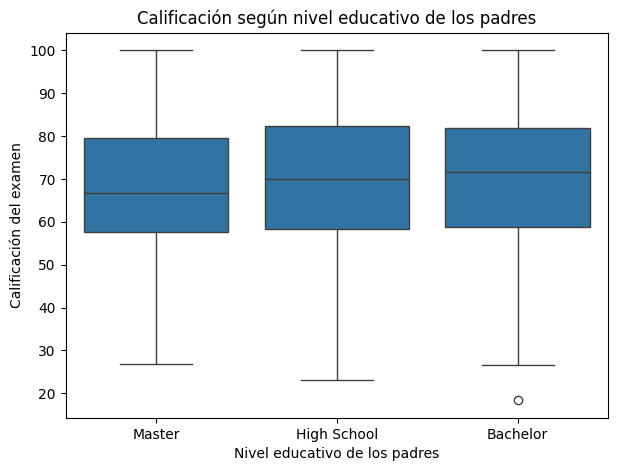

In [156]:
# Gráfica de caja. Mostrar relación entre
# calificaciones de examenes vs nivel de eduación de los padres

plt.figure(figsize=(7,5))

sns.boxplot(
    data=dataset,
    x="parental_education_level",
    y="exam_score"
)

plt.title("Calificación según nivel educativo de los padres")
plt.xlabel("Nivel educativo de los padres")
plt.ylabel("Calificación del examen")

plt.show()

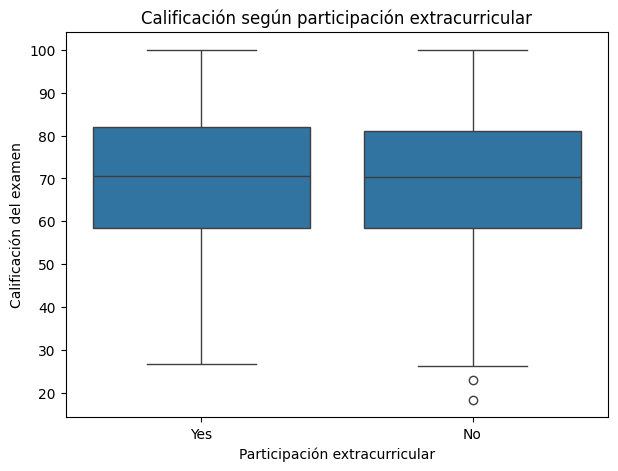

In [157]:
# Gráfica de caja. Mostrar relación entre
# calificaciones de examenes vs participación extracurricular

plt.figure(figsize=(7,5))

sns.boxplot(
    data=dataset,
    x="extracurricular_participation",
    y="exam_score"
)

plt.title("Calificación según participación extracurricular")
plt.xlabel("Participación extracurricular")
plt.ylabel("Calificación del examen")
plt.show()


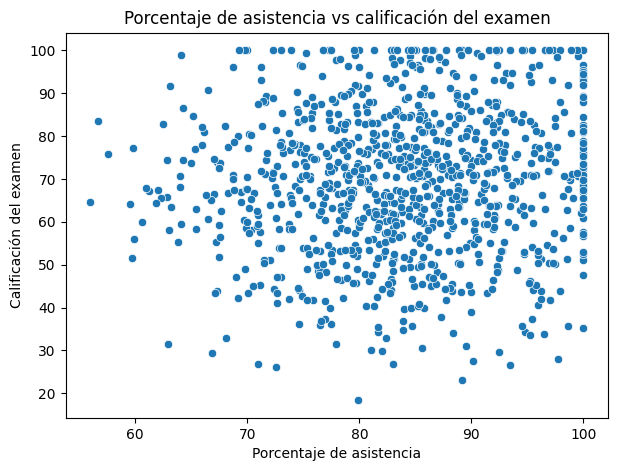

In [158]:
# Gráfica de disperción. Mostrar relación entre
# calificaciones de examenes vs porcentaje de asistencia

plt.figure(figsize=(7,5))

sns.scatterplot(
    data=dataset,
    x="attendance_percentage",
    y="exam_score"
)

plt.title("Porcentaje de asistencia vs calificación del examen")
plt.xlabel("Porcentaje de asistencia")
plt.ylabel("Calificación del examen")
plt.show()

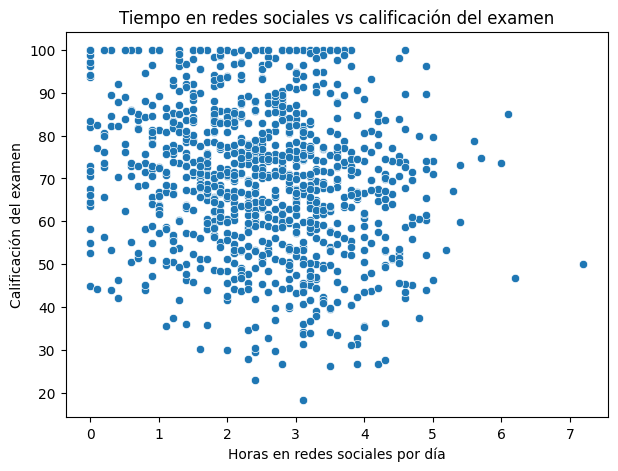

In [159]:
# Gráfica de caja. Mostrar relación entre
# calificaciones de examenes vs horas en redes sociales al día

plt.figure(figsize=(7,5))

sns.scatterplot(
    data=dataset,
    x="social_media_hours",
    y="exam_score"
)

plt.title("Tiempo en redes sociales vs calificación del examen")
plt.xlabel("Horas en redes sociales por día")
plt.ylabel("Calificación del examen")
plt.show()

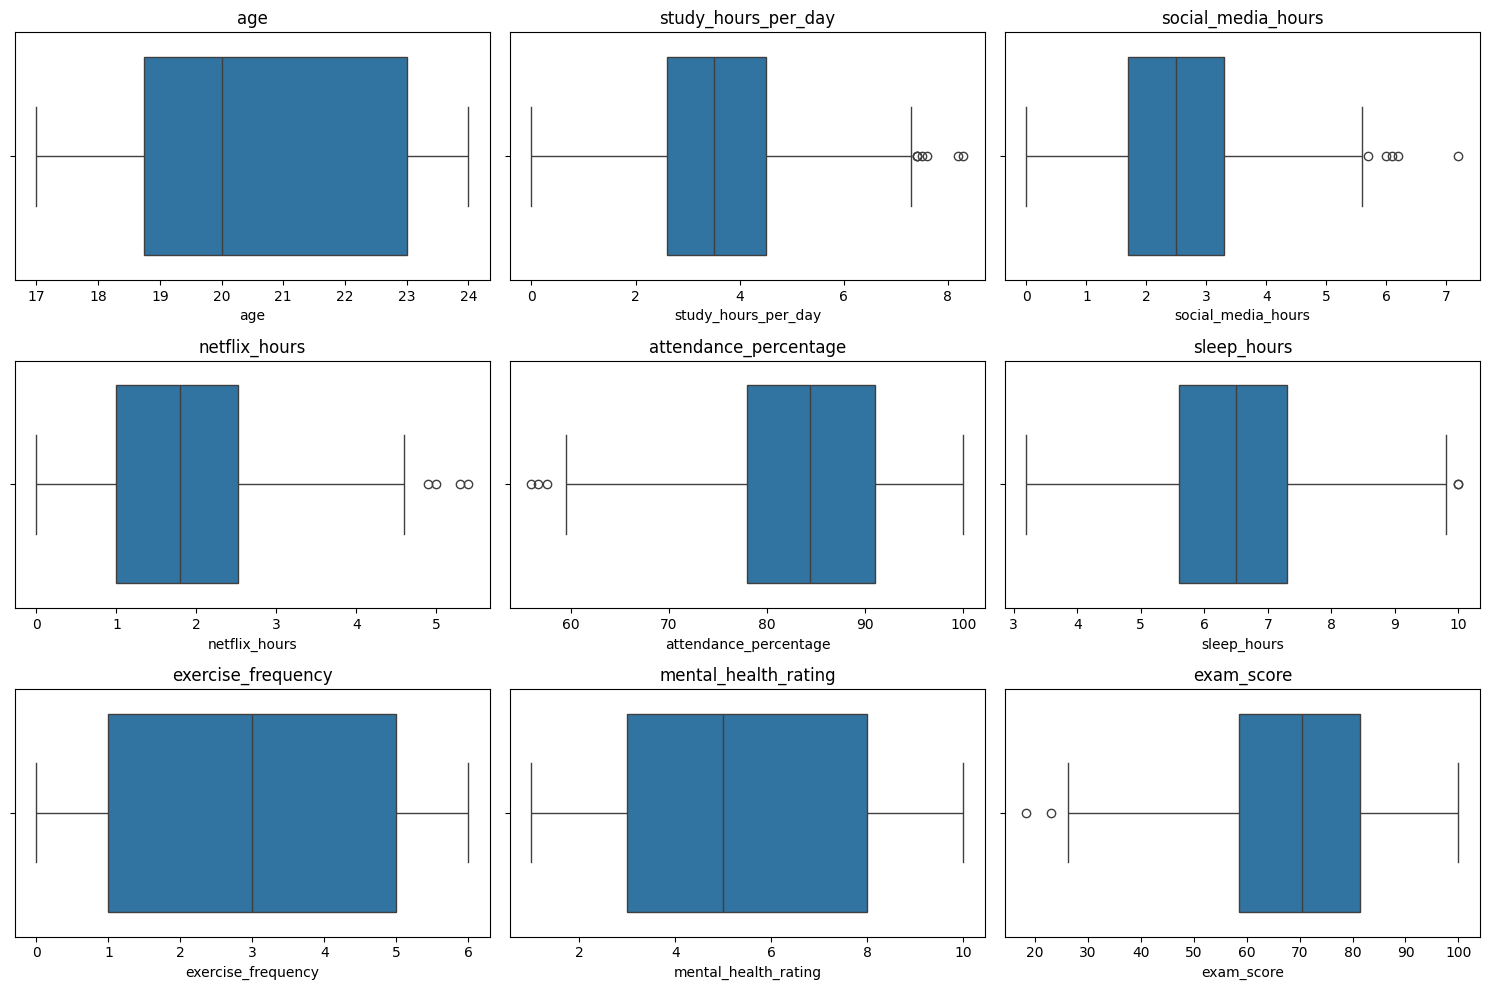

In [160]:
# Gráficas de caja de cada característica numérica

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.ravel()

for col, ax in zip(nums, axes):
    sns.boxplot(x=dataset[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

*Análisis exploratorio de los datos.*

El conjunto de datos contiene 1,000 estudiantes y presenta variables tanto numéricas como categóricas relacionadas con sus hábitos y desempeño académico. En las variables numéricas se observan diferentes escalas y distribuciones. La calificación del examen (exam_score) presenta una media de aproximadamente 69.6 puntos, con valores entre 18.4 y 100, mientras que los estudiantes dedican en promedio 3.55 horas diarias al estudio. La asistencia promedio es de aproximadamente 84.1 % y el promedio de sueño es de 6.47 horas diarias.

En las variables categóricas se observa una distribución relativamente equilibrada entre estudiantes identificados como Female y Male, con una menor representación de la categoría Other. Algunas variables presentan mayor concentración en una categoría; por ejemplo, la mayoría de los estudiantes no cuenta con un trabajo de medio tiempo y tampoco participa en actividades extracurriculares. Asimismo, se identificaron 91 valores faltantes en parental_education_level, los cuales deberán tratarse posteriormente durante la etapa de limpieza.

El análisis de correlación muestra que study_hours_per_day es la variable numérica con mayor relación lineal con exam_score, con un coeficiente de aproximadamente 0.83, lo que indica una asociación positiva fuerte: en general, los estudiantes que dedican más horas al estudio tienden a obtener mejores calificaciones. Esta relación también puede observarse en el diagrama de dispersión.

La segunda asociación positiva más importante corresponde a mental_health_rating, con una correlación aproximada de 0.32, aunque menor que la observada para las horas de estudio. Variables como exercise_frequency, sleep_hours y attendance_percentage presentan asociaciones positivas débiles con la calificación. Por otro lado, social_media_hours y netflix_hours presentan correlaciones negativas débiles, de aproximadamente −0.17, sugiriendo que un mayor tiempo dedicado a estas actividades podría estar asociado con una ligera disminución en el desempeño académico.
Finalmente, age presenta una correlación prácticamente nula con exam_score. Sin embargo, una correlación lineal baja no implica necesariamente que una variable carezca de utilidad predictiva, ya que podrían existir relaciones no lineales o interacciones entre diferentes características. Por esta razón, en esta etapa no se descartarán variables únicamente a partir de su coeficiente de correlación.


## Paso 3. Limpieza los datos.

**Valores duplicados**

In [161]:
# Mostrar datos duplicados

dataset.duplicated().sum()

np.int64(0)

*Análisis de duplicados.* No hay ningún dato duplicado dentro del conjunto de datos, por lo que no se debe de realizar ningún cambio por este factor.

**Valores nulos**

In [162]:
# Mostrar variables con datos nulos

missing_values = dataset.isna().sum()
missing_values[missing_values > 0]

parental_education_level    91
dtype: int64

In [163]:
porcentaje_nulos = (dataset['parental_education_level'].isna().sum()/len(dataset['parental_education_level'])) * 100
print(f"Tenemos un porcentaje del {porcentaje_nulos}% de nulos del total de registros en la variable parental_education_level")

Tenemos un porcentaje del 9.1% de nulos del total de registros en la variable parental_education_level


In [164]:
#Identificar la moda y sustituir los valores nulos por su valor.

moda_estudios_padres = dataset["parental_education_level"].mode()[0]
print("Moda:", moda_estudios_padres)

# Proceso de realizará dentro del pipeline de prepocesamiento

#dataset["parental_education_level"] = (
#    dataset["parental_education_level"].fillna(moda_estudios_padres)
#)
#Veririficación de limpieza de valores nulos.
#dataset["parental_education_level"].isnull().sum()

Moda: High School


*Análisis de nulos.*

Se identificaron 91 valores faltantes en la variable categórica parental_education_level, correspondientes al 9.1% de los registros. Debido a que se trata de una variable categórica y se busca conservar todas las observaciones disponibles, los valores faltantes serán sustituidos por la moda de la variable (en la etapa 4. Entrena un modelo base). De esta manera se evita eliminar registros completos por la ausencia de una sola característica. Se reconoce que este método puede incrementar la representación de la categoría más frecuente; sin embargo, se considera una estrategia sencilla y adecuada para el modelo baseline.

**Valores atípicos (Outliers)**

In [165]:
# Detección de posibles outliers mediante IQR

for col in dataset[nums]:
    Q1 = dataset[col].quantile(0.25)
    Q3 = dataset[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = dataset[(dataset[col] < lower_limit) | (dataset[col] > upper_limit)]

    print(
        f"{col}: \n{len(outliers)} outliers "
        f"\nlímites: {lower_limit:.2f} - {upper_limit:.2f} \n"
    )

age: 
0 outliers 
límites: 12.38 - 29.38 

study_hours_per_day: 
7 outliers 
límites: -0.25 - 7.35 

social_media_hours: 
5 outliers 
límites: -0.70 - 5.70 

netflix_hours: 
4 outliers 
límites: -1.29 - 4.81 

attendance_percentage: 
3 outliers 
límites: 58.46 - 110.56 

sleep_hours: 
2 outliers 
límites: 3.05 - 9.85 

exercise_frequency: 
0 outliers 
límites: -5.00 - 11.00 

mental_health_rating: 
0 outliers 
límites: -4.50 - 15.50 

exam_score: 
2 outliers 
límites: 24.20 - 115.60 



In [166]:
# Identificación de los valores atípicos de cara variable

for col in dataset[nums]:
    Q1 = dataset[col].quantile(0.25)
    Q3 = dataset[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = dataset.loc[
        (dataset[col] < lower_limit) |
        (dataset[col] > upper_limit),
        col
    ]

    if len(outliers) > 0:
        print(f"{col}:")
        print(outliers.to_list())
        print()

study_hours_per_day:
[7.4, 7.4, 8.3, 7.4, 7.5, 8.2, 7.6]

social_media_hours:
[6.2, 6.0, 6.1, 5.7, 7.2]

netflix_hours:
[5.0, 5.4, 5.3, 4.9]

attendance_percentage:
[57.6, 56.7, 56.0]

sleep_hours:
[10.0, 10.0]

exam_score:
[18.4, 23.1]



*Análisis de valores atípicos:*

Mediante el método del rango intercuartílico (IQR) se identificaron posibles valores atípicos en las variables study_hours_per_day, social_media_hours, netflix_hours, attendance_percentage, sleep_hours y exam_score. Posteriormente, los valores detectados fueron inspeccionados individualmente.

Aunque estos registros se encuentran fuera de los límites establecidos por el criterio de 1.5 veces el IQR, los valores observados son validos dentro del contexto de cada variable. Por ejemplo, se identificaron estudiantes con 10 horas de sueño, entre 7.4 y 8.3 horas de estudio diario y calificaciones de 18.4 y 23.1 puntos. Estos valores representan casos extremos, pero no indican necesariamente errores de captura.
Por esta razón, se decidió conservar los valores atípicos, evitando eliminar observaciones válidas o introducir un sesgo en el conjunto de datos. En particular, se conservaron los valores extremos de exam_score, ya que representan estudiantes con bajo desempeño que forman parte de la población que se desea modelar.

**Tipo de dato de las variables**

In [167]:
# Establecer la variable diet_quality como categorica orginal 

dataset["diet_quality"] = pd.Categorical(
    dataset["diet_quality"],
    categories=["Poor", "Fair", "Good"],
    ordered=True
)

# Establecer la variable internet_quality como categorica orginal 

dataset["internet_quality"] = pd.Categorical(
    dataset["internet_quality"],
    categories=["Poor", "Average", "Good"],
    ordered=True
)

# Establecer la variable parental_education_level como categorica orginal 

dataset["parental_education_level"] = pd.Categorical(
    dataset["parental_education_level"],
    categories=["High School", "Bachelor", "Master"],
    ordered=True
)

In [168]:
# Establecer la variable diet_quality como categorica
dataset["gender"] = pd.Categorical(
    dataset["gender"],
    ordered=False
)

dataset["part_time_job"] = pd.Categorical(
    dataset["part_time_job"]
)

dataset["extracurricular_participation"] = pd.Categorical(
    dataset["extracurricular_participation"]
)

In [169]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, S1000 to S1999
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   age                            1000 non-null   int64   
 1   gender                         1000 non-null   category
 2   study_hours_per_day            1000 non-null   float64 
 3   social_media_hours             1000 non-null   float64 
 4   netflix_hours                  1000 non-null   float64 
 5   part_time_job                  1000 non-null   category
 6   attendance_percentage          1000 non-null   float64 
 7   sleep_hours                    1000 non-null   float64 
 8   diet_quality                   1000 non-null   category
 9   exercise_frequency             1000 non-null   int64   
 10  parental_education_level       909 non-null    category
 11  internet_quality               1000 non-null   category
 12  mental_health_rating           100

*Revisión y ajuste de tipos de variables*


Durante la revisión de los tipos de datos se identificó que algunas variables almacenadas inicialmente como object corresponden conceptualmente a variables categóricas. Las variables diet_quality, internet_quality y parental_education_level presentan además un orden natural entre sus categorías, por lo que fueron identificadas como variables categóricas ordinales. Por otro lado, gender corresponde a una variable categórica nominal, mientras que part_time_job y extracurricular_participation son variables categóricas binarias.

En esta etapa se conserva su naturaleza categórica y no se realiza todavía su transformación a valores numéricos.

## Paso 4. Entrenamineto del modelo base.

In [170]:
# División de variable objetivo

X = dataset.drop("exam_score", axis = 1)
y = dataset["exam_score"]

In [171]:
# División de conjuto de entrenamiento y prueba

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state = 1234
)

print("Tamaño del conjuto de características de entrenamiento: ", X_train.shape[0])
print("Tamaño de la variable objetivo de entrenamiento: ", y_train.shape[0])
print("Tamaño del conjuto de características de prueba: ", X_test.shape[0])
print("Tamaño de la variable objetivo de entrenamiento: ", y_test.shape[0])

Tamaño del conjuto de características de entrenamiento:  800
Tamaño de la variable objetivo de entrenamiento:  800
Tamaño del conjuto de características de prueba:  200
Tamaño de la variable objetivo de entrenamiento:  200


*División de los datos.*

Se dividieron los datos en conjuntos de entrenamiento (80%) y prueba (20%). El conjunto de entrenamiento será utilizado para ajustar el preprocesamiento y entrenar el modelo, mientras que el conjunto de prueba se mantendrá separado para evaluar su capacidad de generalización sobre datos no utilizados durante el entrenamiento. Se estableció random_state=1234 para garantizar la reproducibilidad del experimento.

In [172]:
# Agrupación de características por tipo de dato

num_features = [
    "age",
    "study_hours_per_day",
    "social_media_hours",
    "netflix_hours",
    "attendance_percentage",
    "sleep_hours",
    "exercise_frequency",
    "mental_health_rating"
]

ord_features = [
    "diet_quality",
    "internet_quality",
    "parental_education_level"
]

nom_features = [
    "gender",
    "part_time_job",
    "extracurricular_participation"
]

In [173]:
# Declaración del flujo para variables categóricas ordinales

ord_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(
        categories=[
            ["Poor", "Fair", "Good"],              # diet_quality
            ["Poor", "Average", "Good"],           # internet_quality
            ["High School", "Bachelor", "Master"]  # parental_education_level
        ]
    ))
])

In [174]:
# Declaración del flujo de preprocesamiento para variables categóricas nominales
# Codificación One-Hot para variables categóricas nominales

nom_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [175]:
# Normalización de las variables numéricas mediante Min-Max Scaling

num_transformer = Pipeline(steps=[
    ("scaler", MinMaxScaler())
])

In [176]:
# Integración de los flujos de preprocesamiento según el tipo de variable 

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, num_features),
        ("ord", ord_transformer, ord_features),
        ("nom", nom_transformer, nom_features)
    ]
)

In [177]:
# Integración del preprocesamiento y el modelo de regresión en un único Pipeline

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [178]:
# Ajustar el preprocesamiento y entrenar el modelo con los datos de entrenamiento

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   MinMaxScaler())]),
                                                  ['age', 'study_hours_per_day',
                                                   'social_media_hours',
                                                   'netflix_hours',
                                                   'attendance_percentage',
                                                   'sleep_hours',
                                                   'exercise_frequency',
                                                   'mental_health_rating']),
                                                 ('ord',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ordinal',
                                                                   OrdinalEncoder(categories=[['Poor',
                                                                                               'Fair',
                                                                                               'Good'],
                                                                                              ['Poor',
                                                                                               'Average',
                                                                                               'Good'],
                                                                                              ['High '
                                                                                               'School',
                                                                                               'Bachelor',
                                                                                               'Master']]))]),
                                                  ['diet_quality',
                                                   'internet_quality',
                                                   'parental_education_level']),
                                                 ('nom',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'part_time_job',
                                                   'extracurricular_participation'])])),
                ('regressor', LinearRegression())])

In [179]:
# Cálculo de predicciones en base al conjuto de pruebas

y_pred = model.predict(X_test)

In [180]:
# Mostrar valores reales vs. predicciones

results = pd.DataFrame({
    "Real": y_test,
    "Predicción": y_pred
})

results.head(10)

,Real,Predicción
student_id,,
S1681,51.5,54.063442
S1990,63.6,60.557569
S1155,57.3,55.411206
S1768,74.0,77.421993
S1438,66.8,62.764670
S1363,56.9,51.572431
S1688,92.9,94.160443
S1555,83.4,83.680805
S1620,39.8,37.312020


## Paso 5. Evaluación del modelo.

In [181]:
# Cálculo de métricas de evaluación del modelo de regresión lineal.

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  4.670
RMSE: 5.599
R²:   0.900


In [182]:
y_train_pred = model.predict(X_train)

mae_train = mean_absolute_error(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
r2_train = r2_score(y_train, y_train_pred)

print(f"MAE Train:  {mae_train:.3f}")
print(f"MAE Test:   {mae:.3f}")

print(f"\nRMSE Train: {rmse_train:.3f}")
print(f"RMSE Test:  {rmse:.3f}")

print(f"\nR² Train:   {r2_train:.3f}")
print(f"R² Test:    {r2:.3f}")

MAE Train:  4.105
MAE Test:   4.670

RMSE Train: 5.245
RMSE Test:  5.599

R² Train:   0.901
R² Test:    0.900


*Evaluación del modelo.*

El modelo de regresión lineal obtuvo un MAE de 4.670, lo que indica que las predicciones difieren de las calificaciones reales en aproximadamente 4.67 puntos en promedio. 

El RMSE fue de 5.599; al ser ligeramente superior al MAE, indica la presencia de algunos errores de mayor magnitud, aunque la diferencia entre ambas métricas no sugiere que estos dominen el desempeño general del modelo. 

Finalmente, se obtuvo un coeficiente de determinación R² de 0.900, indicando que el modelo explica aproximadamente el 90% de la variabilidad de las calificaciones en el conjunto de prueba. En conjunto, los resultados muestran un buen desempeño para un modelo baseline de regresión lineal, aunque estos resultados deben interpretarse sobre datos no utilizados durante el entrenamiento y no implican necesariamente que el modelo capture relaciones causales entre los hábitos de los estudiantes y su desempeño académico.

Para verificar la capacidad de generalización del modelo, se compararon las métricas obtenidas en los conjuntos de entrenamiento y prueba. El MAE fue de 4.105 en entrenamiento y 4.670 en prueba, mientras que el RMSE fue de 5.245 y 5.599, respectivamente. Por su parte, el R² se mantuvo prácticamente constante, con 0.901 en entrenamiento y 0.900 en prueba.  

Las diferencias entre ambos conjuntos son reducidas, especialmente en el coeficiente R², lo que indica que el desempeño del modelo se mantiene al utilizar datos que no fueron empleados durante el entrenamiento. Por lo tanto, no se observa evidencia significativa de sobreajuste. El modelo de regresión lineal utilizado como baseline presenta una buena capacidad de generalización para este conjunto de datos.

## Paso 6. Registro del experimento en MLFlow.

In [183]:
# Declaración del url para el servidor de mlflow
mlflow.set_tracking_uri(uri = "http://127.0.0.1:5000")

# Definición del experimento
mlflow.set_experiment("Student_Performance_Baseline")

with mlflow.start_run(run_name="LinearRegression_Baseline"):

    # Registro de los parámetros utilizados en el experimento
    mlflow.log_param("model", "LinearRegression")
    mlflow.log_param("test_size", 0.20)
    mlflow.log_param("random_state", 1234)
    mlflow.log_param("numeric_scaler", "MinMaxScaler")
    mlflow.log_param("ordinal_encoder", "OrdinalEncoder")
    mlflow.log_param("nominal_encoder", "OneHotEncoder")
    mlflow.log_param("imputation", "most_frequent")

    # Registro de las métricas de desempeño para entrenamiento y prueba
    mlflow.log_metric("mae_train", mae_train)
    mlflow.log_metric("mae_test", mae)
    mlflow.log_metric("rmse_train", rmse_train)
    mlflow.log_metric("rmse_test", rmse)
    mlflow.log_metric("r2_train", r2_train)
    mlflow.log_metric("r2_test", r2)

    signature = infer_signature(
    X_train,
    model.predict(X_train)
    )
    
    # Registro del modelo entrenado como artefacto en MLflow
    mlflow.sklearn.log_model(
        model,
        name="student_performance_model",
        signature= signature,
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList"
            ]
            )

c:\Users\jimen\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run LinearRegression_Baseline at: http://127.0.0.1:5000/#/experiments/5/runs/6650320879ec47f0b6069d0a18535f1a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5


*Registro del experimento con MLflow.*

El modelo baseline fue registrado mediante MLflow con el objetivo de mantener la trazabilidad y reproducibilidad del experimento. Se almacenaron los principales parámetros utilizados durante el preprocesamiento y entrenamiento, incluyendo la división train/test, el escalamiento Min-Max, la codificación de variables categóricas y la estrategia de imputación. Asimismo, se registraron las métricas MAE, RMSE y R² tanto para entrenamiento como para prueba. Finalmente, se almacenó el pipeline completo, incluyendo las transformaciones de preprocesamiento y el modelo de regresión lineal, permitiendo conservar en un mismo artefacto el flujo necesario para realizar futuras predicciones.

*Evidencias del experimento Student_Performance_Baseline registrado en MLFlow*

In [184]:
# Cargar capturas de la interfaz de MLFlow como evidencia del experimento registrado

experiment = cv2.imread('experimento.png')
experiment = cv2.cvtColor(experiment, cv2.COLOR_BGR2RGB)

metricas = cv2.imread('metrics.png')
metricas = cv2.cvtColor(metricas, cv2.COLOR_BGR2RGB)

run = cv2.imread('run.png')
run = cv2.cvtColor(run, cv2.COLOR_BGR2RGB)

artifacts = cv2.imread('artifact.png')
artifacts = cv2.cvtColor(artifacts, cv2.COLOR_BGR2RGB)

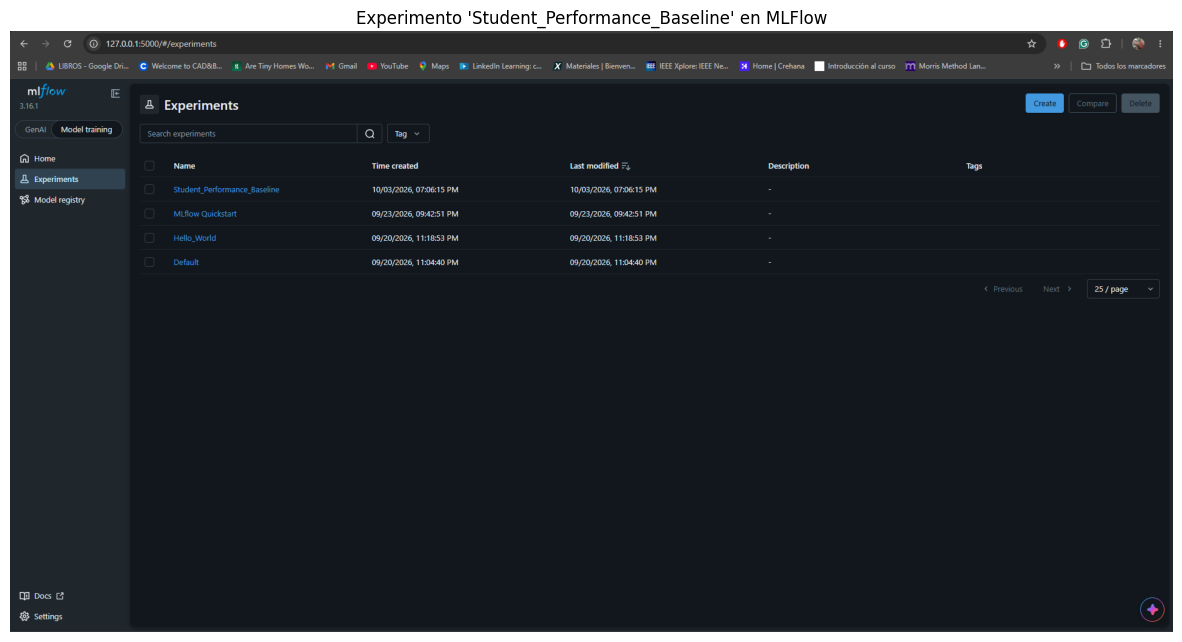

In [185]:
# Mostrar evidencia del experimento registrado en MLFlow
plt.figure(figsize=(15, 8))
plt.imshow(experiment)
plt.title("Experimento 'Student_Performance_Baseline' en MLFlow")
plt.axis("off")
plt.show()

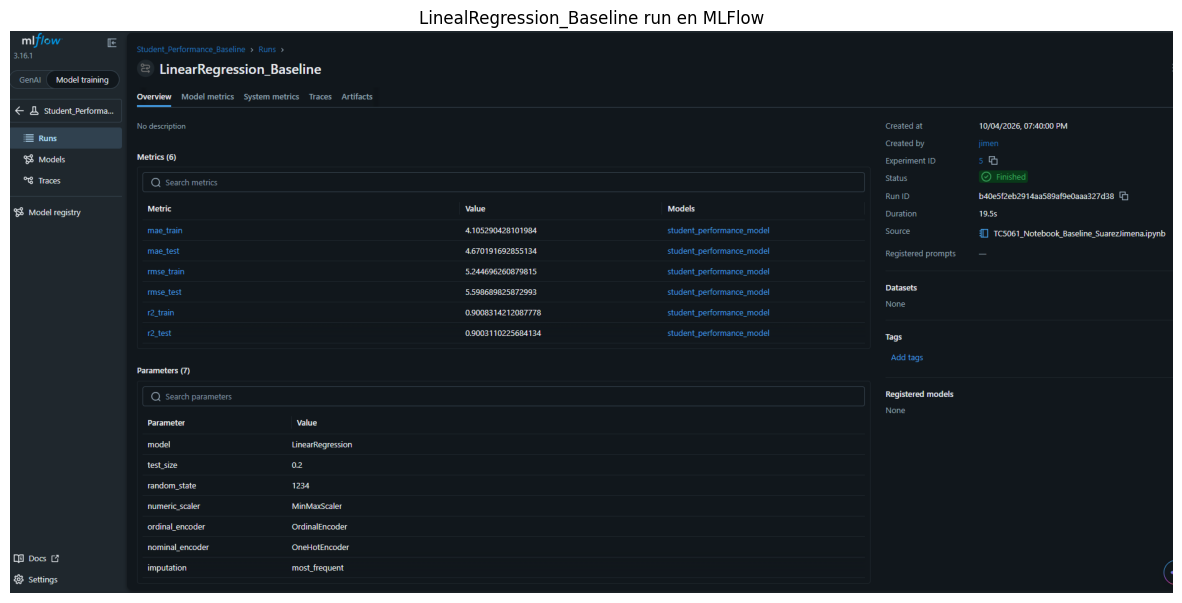

In [186]:
# Mostrar evidencia de la corrida de LinearRegression_Baseline

plt.figure(figsize=(15, 8))
plt.imshow(run)
plt.title("LinealRegression_Baseline run en MLFlow")
plt.axis("off")
plt.show()

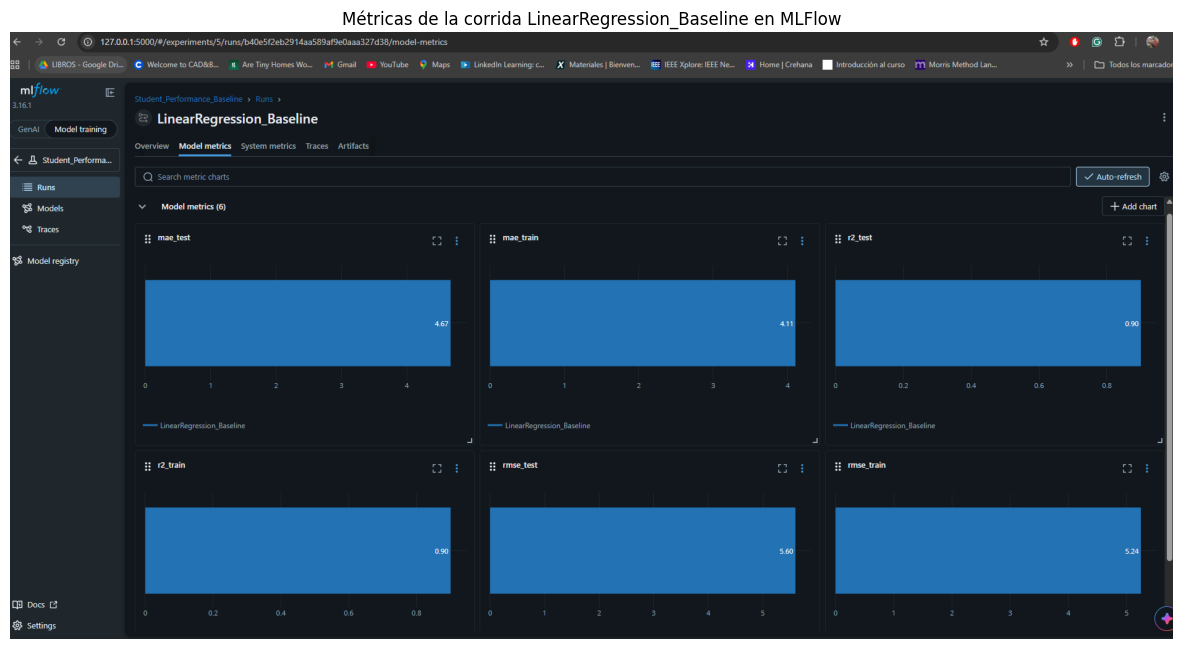

In [189]:
# Mostrar evidencia de las métricas en la corrida de LinearRegression_Baseline

plt.figure(figsize=(15, 8))
plt.imshow(metricas)
plt.title("Métricas de la corrida LinearRegression_Baseline en MLFlow")
plt.axis("off")
plt.show()

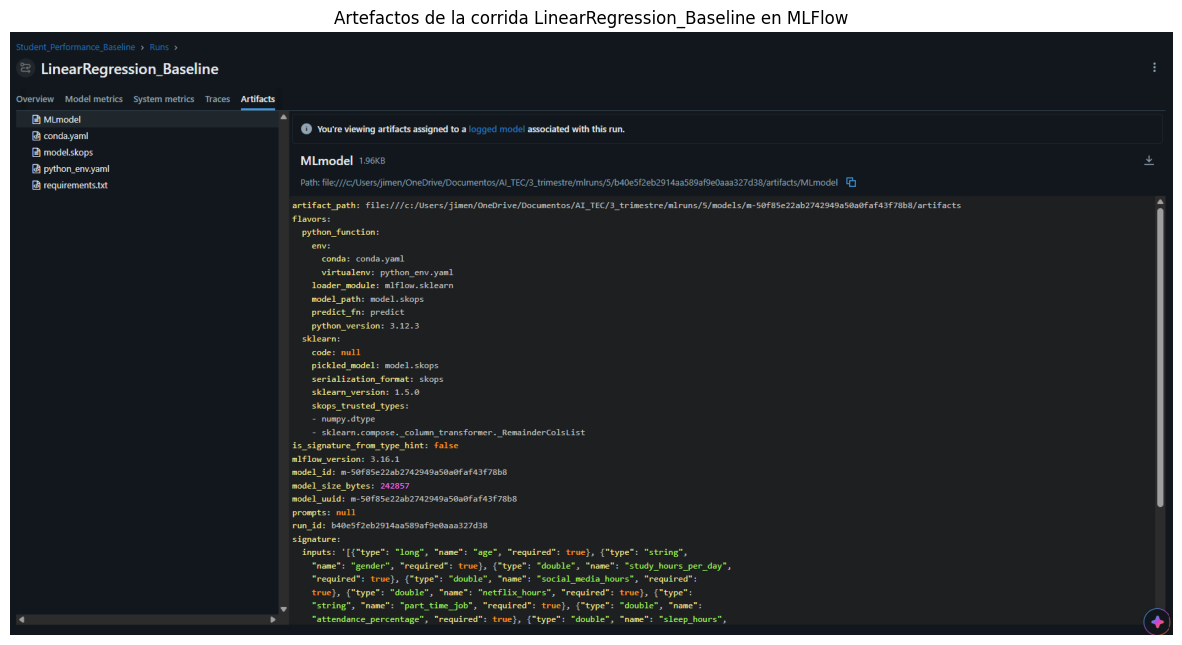

In [188]:
# Mostrar evidencia de los artefactos en la corrida de LinearRegression_Baseline

plt.figure(figsize=(15, 8))
plt.imshow(artifacts)
plt.title("Artefactos de la corrida LinearRegression_Baseline en MLFlow")
plt.axis("off")
plt.show()

## Paso 7. Reflexión.



**¿Qué mejoras de MLOps aplicarías a este proyecto?**

A partir del desarrollo de este proyecto, considero que una de las principales mejoras sería fortalecer la automatización y reproducibilidad del flujo completo de Machine Learning. Aunque en este ejercicio se utilizó un pipeline para integrar el preprocesamiento y el modelo, sería conveniente incorporar también mecanismos para versionar tanto los datos como el código utilizado en cada experimento. Esto permitiría conocer exactamente con qué conjunto de datos, transformaciones y versión del modelo se obtuvo cada resultado.

Otra mejora sería ampliar el uso de MLflow para comparar diferentes modelos e hiperparámetros dentro de un mismo experimento. En este caso se utilizó una regresión lineal como baseline y se registraron sus parámetros, métricas y el modelo resultante; sin embargo, posteriormente podrían evaluarse otros algoritmos y comparar sus resultados de manera estructurada. También sería importante automatizar las etapas de entrenamiento, evaluación y validación mediante un pipeline de CI/CD, estableciendo criterios mínimos de desempeño antes de aceptar una nueva versión del modelo.

Finalmente, si el modelo fuera desplegado en un ambiente productivo, agregaría monitoreo para detectar cambios en los datos y degradación en el desempeño del modelo. De esta manera, MLOps permitiría que el proyecto no terminara únicamente con el entrenamiento, sino que pudiera mantenerse y evolucionar de manera controlada.


**¿Cómo se relaciona MLOps con tu experiencia profesional?**

Las prácticas de MLOps se relacionan mucho con mi experiencia profesional en automatización, pruebas y validación de sistemas. En los proyectos en los que he trabajado, la trazabilidad y la reproducibilidad son fundamentales, ya que no basta con saber que una prueba fue exitosa; también es necesario conocer bajo qué configuración se ejecutó, qué versión se utilizó y cuáles fueron los resultados obtenidos. Durante esta actividad encontré una relación muy similar con Machine Learning (Uso de MLFlow): obtener un modelo con buen desempeño no es suficiente si posteriormente no es posible reproducir las condiciones con las que fue generado.

El uso de MLflow me permitió visualizar esta relación de manera más clara, ya que fue posible registrar en un mismo experimento los parámetros de preprocesamiento, las métricas de entrenamiento y prueba y el modelo generado. Esta forma de trabajo es similar a los procesos de automatización y validación en los que se busca mantener evidencia y seguimiento de cada ejecución. 

Considero que integrar conocimientos de MLOps con mi experiencia en automatización puede ser especialmente útil para desarrollar sistemas de inteligencia artificial más confiables, mantenibles y reproducibles, principalmente en aplicaciones donde un modelo forma parte de un sistema de ingeniería más grande.

*Referencias bibliográficas.*


1. Jayaantanaath. (s. f.). Student habits vs academic performance [Data set]. Kaggle. Student Habits vs Academic Performance – Kaggle

2. MLflow. (2026). MLflow Tracking Quickstart. MLflow Documentation. MLflow Tracking Quickstart

3. MLflow. (2026). MLflow Tracking. MLflow Documentation. MLflow Tracking Documentation

4. Scikit-learn developers. (2026). Metrics. Scikit-learn Documentation.

5. OpenAI. (2026). ChatGPT [Large language model]. ChatGPT

Uso de inteligencia artificial: Durante el desarrollo de esta actividad se utilizó ChatGPT (OpenAI, 2026) como herramienta de apoyo para la comprensión de conceptos y revisión de código. La información obtenida mediante esta herramienta fue revisada y contrastada con las fuentes bibliográficas y documentación oficial citadas en este trabajo.
